# Comics apps: privacy, predictive features, and monetization

Matias Freer · AN 306 academic portfolio

**My contribution:** Privacy analysis, Random Forest feature importance, monetization analysis, and visualization. Training-fitted imputation and chart values computed from results are portfolio revisions.

See README.md for team credits, findings, limitations, and setup. Original saved work is in original_analysis.ipynb. Data files are excluded from GitHub; place the input under data/ or set AN306_INPUT.

## Analysis implementation

The implementation matches analysis.py. Assertions check key assumptions before creating tables and figures.

In [1]:
"""Portfolio edition: app privacy, feature importance, and monetization.

Starts from the professor-provided cleaned input. Preserves the original
positive-permission population for comparison; does not infer raw join membership.
"""
from pathlib import Path
import argparse
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy.stats import kruskal, mannwhitneyu
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, classification_report

FEATURES = ['sensitive_permission_count', 'permission_count', 'has_privacy_policy',
            'app_age_years', 'days_since_update', 'free', 'ad_supported', 'in_app_purchases']


def load_comics(path):
    # Chunking avoids materializing the multi-million-row input in memory.
    selected = []
    all_rows = 0
    positive_permissions = 0
    for chunk in pd.read_csv(path, chunksize=50000, low_memory=False):
        all_rows += len(chunk)
        positive_permissions += int(pd.to_numeric(chunk.permission_count, errors='coerce').gt(0).sum())
        selected.append(chunk.loc[chunk.category.eq('Comics')].copy())
    df = pd.concat(selected, ignore_index=True)
    for col in ['has_privacy_policy', 'free', 'ad_supported', 'in_app_purchases', 'is_successful']:
        values = df[col].astype(str).str.strip().str.lower()
        assert values.isin(['true', 'false']).all(), f'Unexpected boolean values: {col}'
        df[col] = values.eq('true')
    assert not df.app_id.duplicated().any(), 'Duplicate app IDs need review.'
    expected = df.minimum_installs.ge(100000) & df.rating.ge(4)
    assert df.is_successful.eq(expected).all(), 'Success labels differ from the documented definition.'
    print(f'All input rows: {all_rows:,}; rows with positive permission count: {positive_permissions:,}')
    print(f'All Comics apps: {len(df):,}; positive-permission Comics apps: {df.permission_count.gt(0).sum():,}')
    return df


def main(path, output):
    output = Path(output); output.mkdir(parents=True, exist_ok=True)
    all_comics = load_comics(path)
    comics = all_comics.loc[all_comics.permission_count.gt(0)].copy()
    tiers = ['Minimal', 'Moderate', 'Heavy']
    expected_tiers = pd.cut(comics.sensitive_permission_count, [-1, 0, 2, np.inf], labels=tiers).astype(str)
    assert expected_tiers.eq(comics.privacy_tier).all()
    privacy = comics.groupby('privacy_tier').agg(apps=('app_id', 'size'), successful=('is_successful', 'sum'),
        success_rate=('is_successful', 'mean'), mean_rating=('rating', 'mean')).reindex(tiers)
    privacy.to_csv(output / 'privacy_summary.csv')
    rated = [comics.loc[comics.privacy_tier.eq(t) & comics.rating.gt(0), 'rating'] for t in tiers]
    statistic, p = kruskal(*rated)
    tests = {'kruskal_wallis': {'statistic': float(statistic), 'p_value': float(p)}, 'pairwise': []}
    for a, b in [(0, 1), (0, 2), (1, 2)]:
        test = mannwhitneyu(rated[a], rated[b], alternative='two-sided')
        tests['pairwise'].append({'comparison': f'{tiers[a]} vs {tiers[b]}', 'p_value': float(test.pvalue),
                                  'bonferroni_significant': bool(test.pvalue < .05 / 3)})
    (output / 'statistical_tests.json').write_text(json.dumps(tests, indent=2))
    X = comics[FEATURES].astype(float); y = comics.is_successful.astype(int)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42, stratify=y)
    model = make_pipeline(SimpleImputer(strategy='median'), RandomForestClassifier(
        n_estimators=300, random_state=42, class_weight='balanced', n_jobs=1))
    model.fit(X_train, y_train)
    probabilities = model.predict_proba(X_test)[:, 1]
    metrics = {'roc_auc': float(roc_auc_score(y_test, probabilities)), 'train_apps': len(y_train),
               'test_apps': len(y_test), 'classification_report': classification_report(y_test, model.predict(X_test), output_dict=True, zero_division=0)}
    (output / 'model_metrics.json').write_text(json.dumps(metrics, indent=2))
    importance = permutation_importance(model, X_test, y_test, scoring='roc_auc', n_repeats=20, random_state=42, n_jobs=1)
    imp = pd.DataFrame({'feature': FEATURES, 'importance': importance.importances_mean, 'std': importance.importances_std}).sort_values('importance')
    imp.to_csv(output / 'permutation_importance.csv', index=False)
    def monetization(frame):
        table = frame.groupby('monetization_model').agg(apps=('app_id', 'size'), successful=('is_successful', 'sum'),
            success_rate=('is_successful', 'mean'), mean_rating=('rating', 'mean'), median_minimum_installs=('minimum_installs', 'median'))
        table['market_share'] = table.apps / table.apps.sum()
        table['share_of_successful'] = table.successful / table.successful.sum()
        return table.sort_values('success_rate', ascending=False)
    money = monetization(comics); money.to_csv(output / 'monetization_original_population.csv')
    monetization(all_comics).to_csv(output / 'monetization_all_comics.csv')
    plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    rates = privacy.success_rate * 100
    axes[0].plot(tiers, rates, marker='o', color='#237a91')
    for i, val in enumerate(rates): axes[0].annotate(f'{val:.2f}%', (i, val), xytext=(0, 9), textcoords='offset points', ha='center')
    axes[0].set(ylim=(0, 15), ylabel='Successful apps (%)', title='Similar observed success rates')
    axes[1].boxplot(rated, tick_labels=tiers, showmeans=True, showfliers=False)
    axes[1].set(ylabel='App rating', ylim=(1, 5.2), title='Rating distributions differ by privacy tier')
    fig.text(.5, .01, f'Comics apps with positive recorded permission counts (n={len(comics):,}). Sensitive groups: 0 / 1–2 / 3+.', ha='center', fontsize=9)
    fig.tight_layout(rect=[0, .05, 1, 1]); fig.savefig(output / 'privacy_comparison.png', dpi=170); plt.close(fig)
    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.barh(imp.feature.str.replace('_', ' '), imp.importance, xerr=imp['std'], color='#237a91', capsize=3)
    ax.axvline(0, color='gray', linewidth=.8)
    ax.set(xlabel='Drop in held-out ROC-AUC after permutation', title='App maintenance and age carry the strongest predictive signal')
    fig.text(.12, .01, 'Error bars: standard deviation across 20 permutations; not confidence intervals. Association is not causation.', fontsize=9)
    fig.tight_layout(rect=[0, .05, 1, 1]); fig.savefig(output / 'feature_importance.png', dpi=170); plt.close(fig)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    labels = money.index.str.replace('Freemium ', '').str.replace('Free (no monetization)', 'No listed ads / IAP / price', regex=False)
    axes[0].barh(labels, money.market_share * 100, color='#739bbd')
    axes[1].barh(labels, money.success_rate * 100, color='#18856b')
    axes[0].set(xlabel='Share of apps (%)', title='Prevalence of monetization approaches')
    axes[1].set(xlabel='Successful apps (%)', title='Observed success within each approach')
    fig.text(.5, .01, f'Original positive-permission Comics population (n={len(comics):,}). Success: 100K+ installs and rating ≥4.0.', ha='center', fontsize=9)
    fig.tight_layout(rect=[0, .05, 1, 1]); fig.savefig(output / 'monetization_comparison.png', dpi=170); plt.close(fig)
    print(privacy.round(4).to_string()); print(money.round(4).to_string())
    print(f'Corrected preprocessing ROC-AUC: {metrics["roc_auc"]:.4f}')
    print(imp.sort_values('importance', ascending=False).round(4).to_string(index=False))
    print('Kruskal-Wallis p-value:', p)



## Run

Run from this project folder after installing the repository requirements. Update INPUT_PATH if needed. META users can obtain a fixed-date snapshot with python analysis.py --download first.

In [2]:
import os
INPUT_PATH = os.environ.get('AN306_INPUT', 'data/Andrew_Clean_Dataset.csv')
main(INPUT_PATH, 'results')

All input rows: 2,312,832; rows with positive permission count: 2,219,725
All Comics apps: 2,862; positive-permission Comics apps: 2,738


              apps  successful  success_rate  mean_rating
privacy_tier                                             
Minimal       1104         117        0.1060       3.9961
Moderate       936          93        0.0994       3.9158
Heavy          698          80        0.1146       3.8442
                        apps  successful  success_rate  mean_rating  median_minimum_installs  market_share  share_of_successful
monetization_model                                                                                                             
Freemium (Ads + IAP)     355          78        0.2197       3.9350                  50000.0        0.1297               0.2690
Freemium (IAP only)      117          20        0.1709       3.8495                  10000.0        0.0427               0.0690
Ad-supported            1783         179        0.1004       3.9142                   5000.0        0.6512               0.6172
Free (no monetization)   438          13        0.0297       3.9562   

## Visual findings

All figures below are generated from the run above. Interpretations and limitations are in the project README.

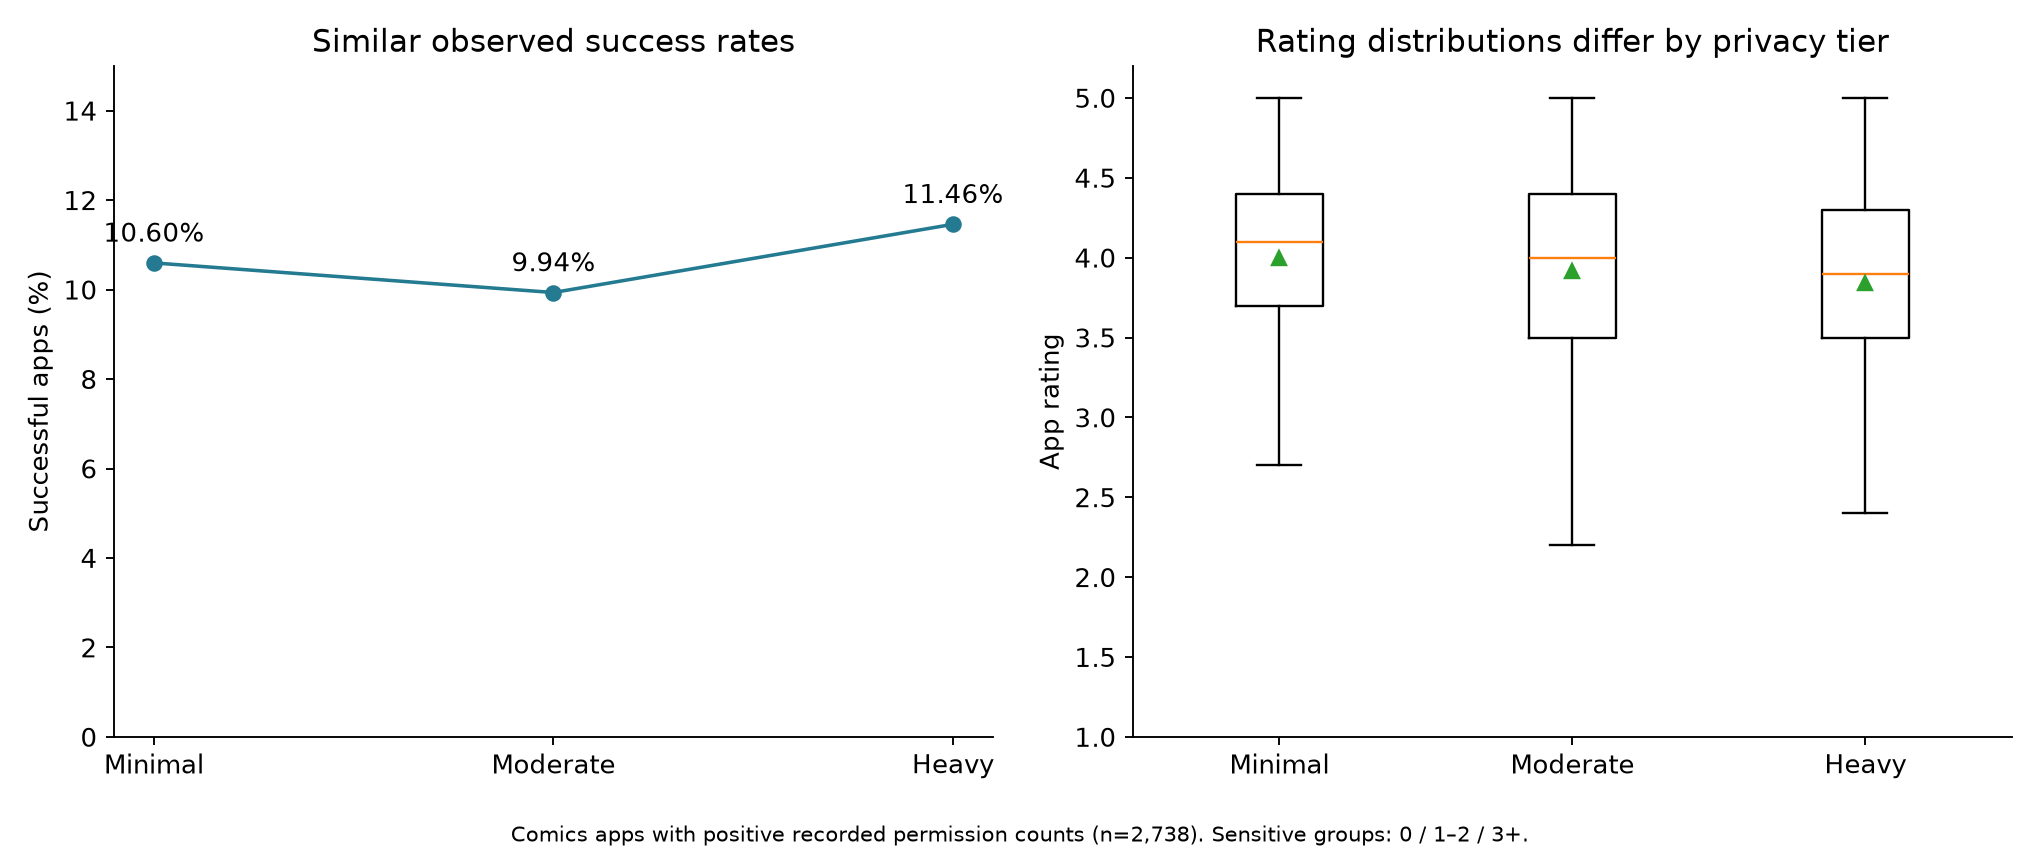

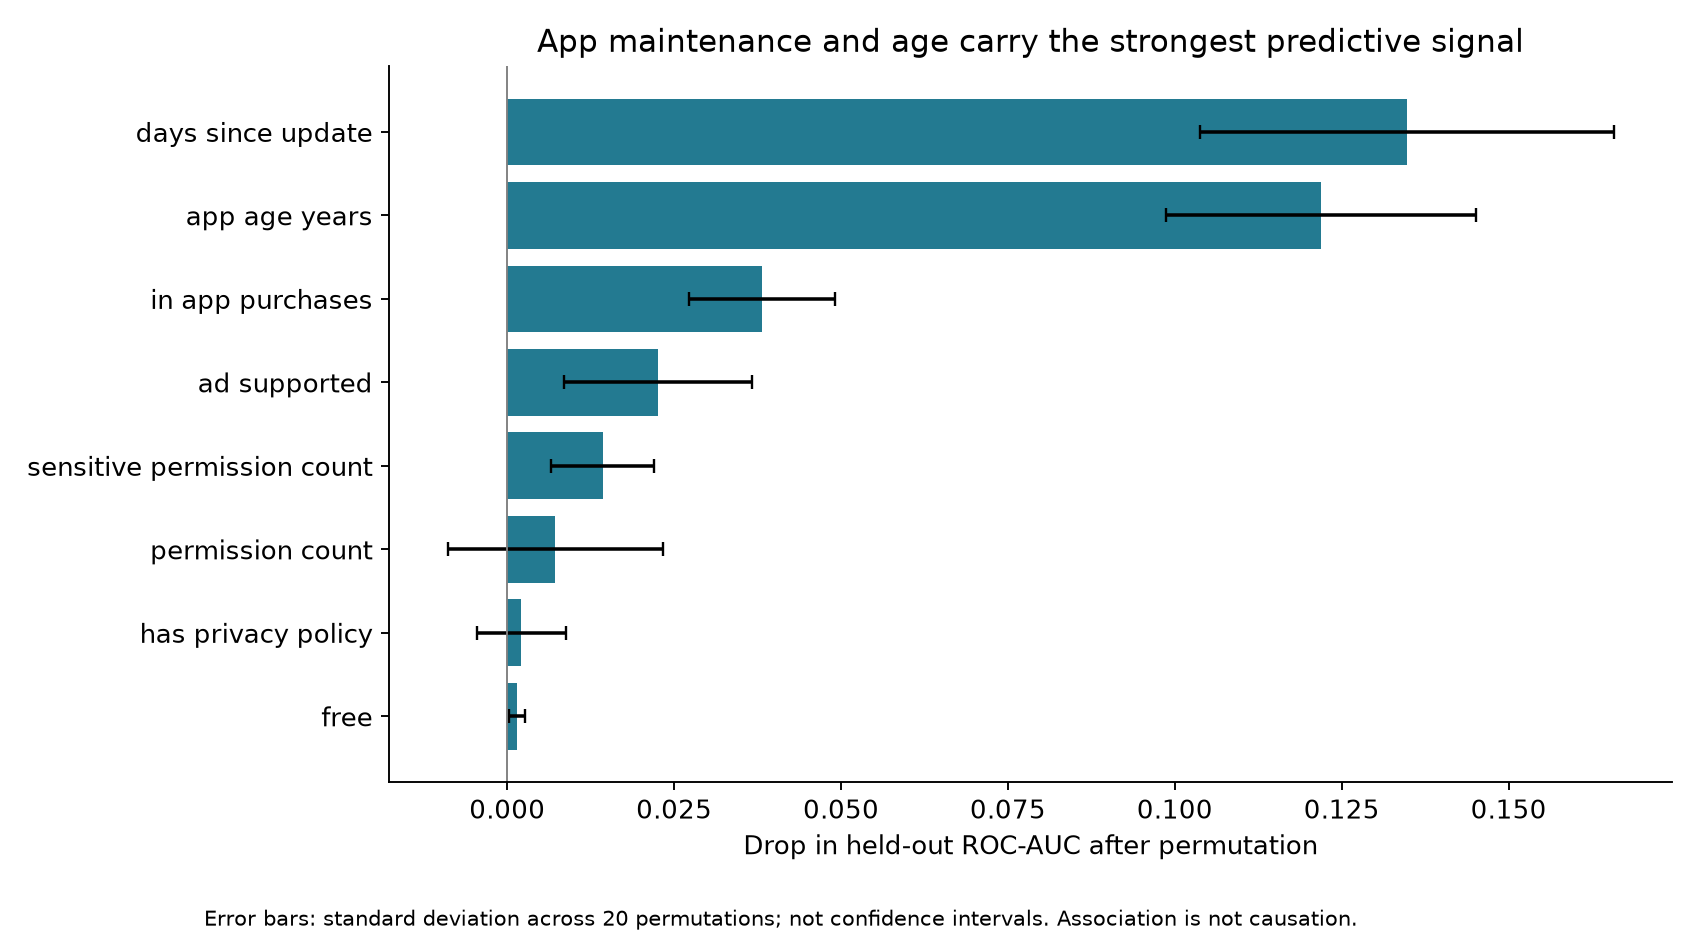

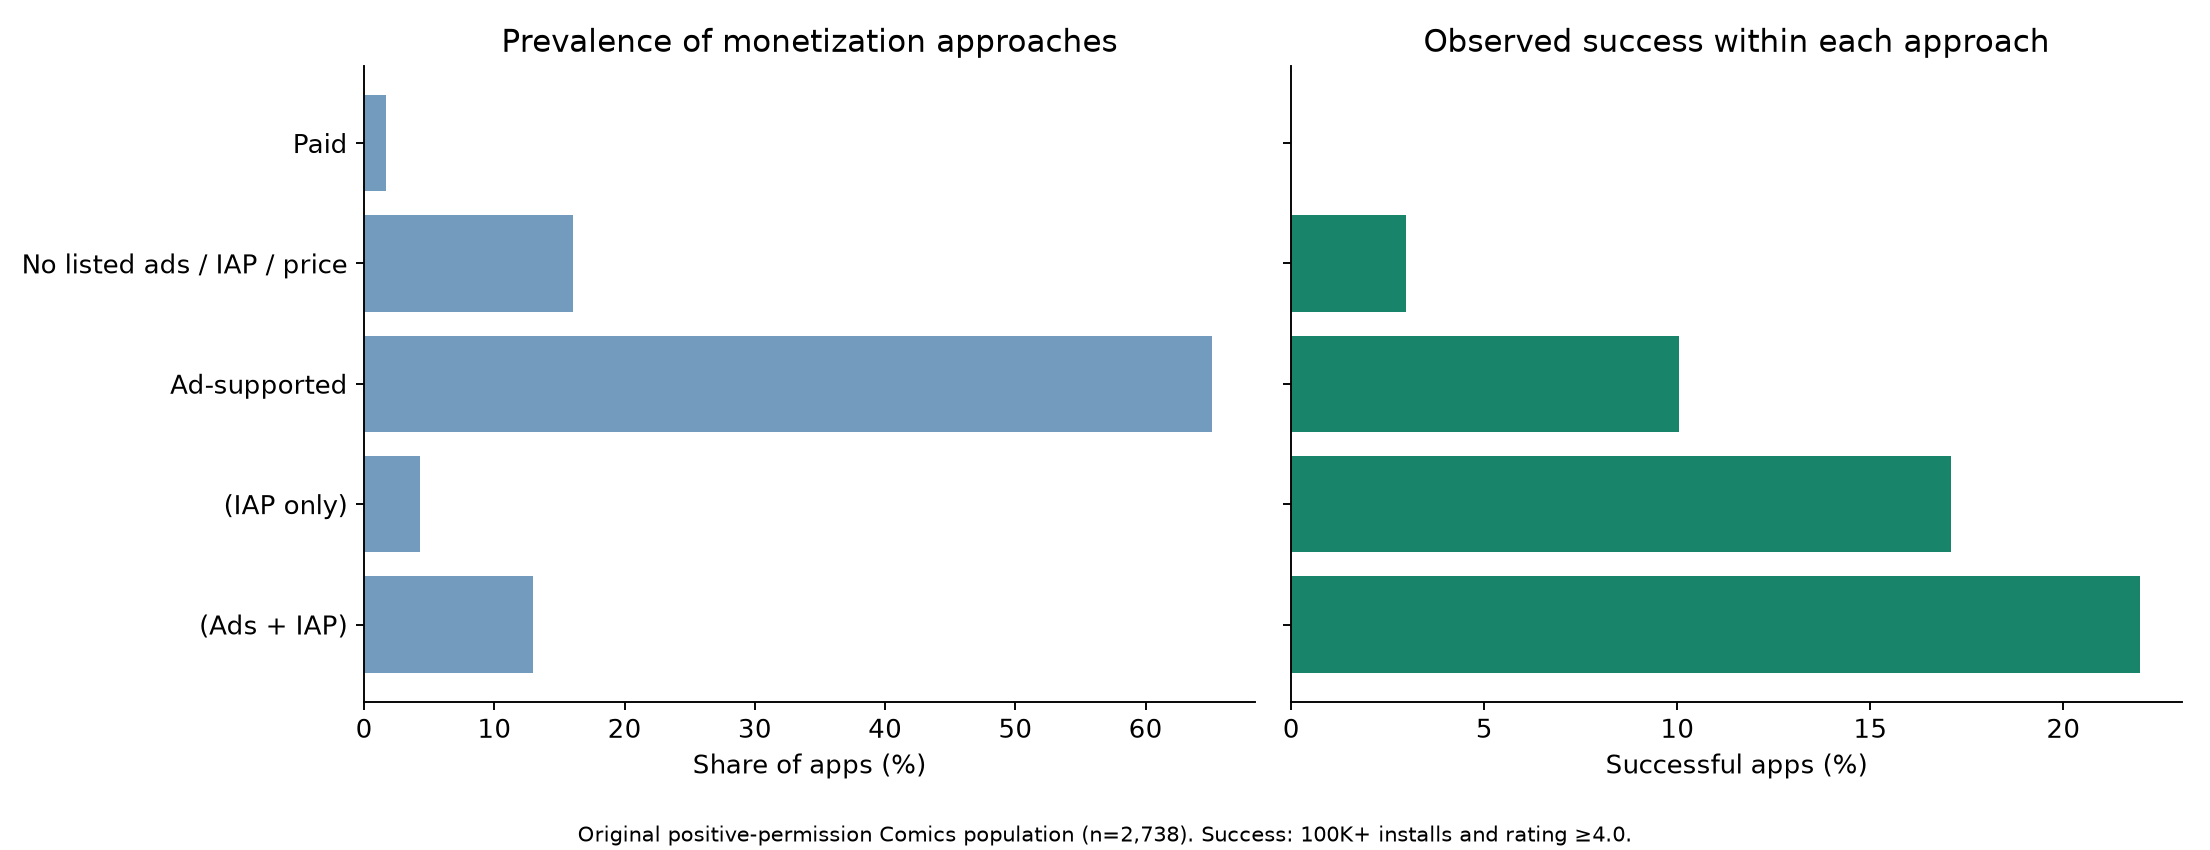

In [3]:
from IPython.display import Image, display
display(Image(filename='results/privacy_comparison.png'))
display(Image(filename='results/feature_importance.png'))
display(Image(filename='results/monetization_comparison.png'))

## Reproducibility

Regenerated for the portfolio on October 28, 2026. See ../VALIDATION.md for comparisons with original course results. Associations and descriptive trend signals do not establish causation or guarantee future outcomes.